# Aprendizaje Automático — Unidad 4: Aprendizaje por Refuerzo
**Cuaderno de trabajo resuelto (Actividades 25 a 30)** · Maestría en Inteligencia Artificial · TecNM Virtual

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alixpeg0/aprendizaje-por-refuerzo-unidad4/blob/main/Unidad4_Aprendizaje_por_Refuerzo.ipynb)

**Contenido:** teoría paso a paso → esquema → Act. 25 → Act. 26 → Act. 27 → Act. 28 → Act. 29 → Act. 30.
Para ejecutar todo: *Entorno de ejecución → Ejecutar todo*. Solo usa numpy, pandas y matplotlib.

## 0. Código base (entorno, Q-learning y figuras)
Ejecuta primero esta celda. Es el mismo archivo `rl_core.py` del repositorio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ----------------------------------------------------------------------------
# 1. Entorno de ejemplo: 3 estados x 3 acciones (determinista)
# ----------------------------------------------------------------------------
ESTADOS = ["S1", "S2", "S3"]
ACCIONES = ["Izquierda", "Derecha", "Quedarse"]


def construir_entorno(r_s3_quedarse=3):
    """Devuelve T[(estado, accion)] = (siguiente_estado, recompensa).

    S1 -- S2 -- S3   (los extremos chocan contra la pared)
    En S3: 'Quedarse' recoge una recompensa r_s3_quedarse (+3 en el original);
    'Izquierda' regresa a S2 con +5 (hay un atajo que rinde bien, pero obliga
    a ir y venir entre S2 y S3).
    """
    return {
        ("S1", "Izquierda"): ("S1", -1),
        ("S1", "Derecha"):   ("S2", 0),
        ("S1", "Quedarse"):  ("S1", 0),
        ("S2", "Izquierda"): ("S1", 0),
        ("S2", "Derecha"):   ("S3", 1),
        ("S2", "Quedarse"):  ("S2", 0),
        ("S3", "Izquierda"): ("S2", 5),
        ("S3", "Derecha"):   ("S3", -1),
        ("S3", "Quedarse"):  ("S3", r_s3_quedarse),
    }


def tabla_entorno(T):
    filas = [(s, a, s2, r) for (s, a), (s2, r) in T.items()]
    return pd.DataFrame(filas, columns=["Estado s", "Acción a", "Siguiente s'", "Recompensa r"])


# ----------------------------------------------------------------------------
# 2. Q-learning: una actualización y una trayectoria
# ----------------------------------------------------------------------------
def q_vacia():
    return pd.DataFrame(0.0, index=ESTADOS, columns=ACCIONES)


def actualizar_q(Q, s, a, r, s2, alpha=0.5, gamma=0.9):
    """Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]"""
    q_old = Q.loc[s, a]
    max_next = Q.loc[s2].max()
    objetivo = r + gamma * max_next
    error_td = objetivo - q_old
    q_new = q_old + alpha * error_td
    Q.loc[s, a] = q_new
    return dict(q_old=q_old, max_next=max_next, objetivo=objetivo, error_td=error_td, q_new=q_new)


TRAYECTORIA = [("S1", "Derecha"), ("S2", "Derecha"), ("S3", "Quedarse"),
               ("S3", "Izquierda"), ("S2", "Derecha"), ("S3", "Izquierda")]


def simular_trayectoria(T, trayectoria=TRAYECTORIA, alpha=0.5, gamma=0.9):
    """Aplica Q-learning paso a paso. Devuelve (Q final, tabla de pasos)."""
    Q = q_vacia()
    filas = []
    for i, (s, a) in enumerate(trayectoria, 1):
        s2, r = T[(s, a)]
        d = actualizar_q(Q, s, a, r, s2, alpha, gamma)
        formula = (f"Q({s},{a}) = {d['q_old']:.4f} + {alpha}·[{r} + {gamma}·{d['max_next']:.4f} "
                   f"− {d['q_old']:.4f}] = {d['q_new']:.4f}")
        filas.append(dict(Paso=i, s=s, a=a, r=r, **{"s'": s2},
                          **{"Q anterior": d["q_old"], "max Q(s',·)": d["max_next"],
                             "Objetivo r+γ·max": d["objetivo"], "Error TD": d["error_td"],
                             "Q nuevo": d["q_new"]}, Cálculo=formula))
    return Q, pd.DataFrame(filas)


# ----------------------------------------------------------------------------
# 3. Solución "exacta" (ecuación de Bellman óptima) y Q-learning entrenado
# ----------------------------------------------------------------------------
def q_optima(T, gamma=0.9, iteraciones=500):
    """Iteración de valor sobre Q: Q(s,a) <- r + gamma * max_a' Q(s',a')."""
    Q = q_vacia()
    for _ in range(iteraciones):
        nueva = Q.copy()
        for (s, a), (s2, r) in T.items():
            nueva.loc[s, a] = r + gamma * Q.loc[s2].max()
        Q = nueva
    return Q


def entrenar_q_learning(T, episodios=500, pasos=20, alpha=0.5, gamma=0.9, eps=0.2, seed=0):
    rng = np.random.default_rng(seed)
    Q = q_vacia()
    for _ in range(episodios):
        s = ESTADOS[rng.integers(3)]
        for _ in range(pasos):
            a = ACCIONES[rng.integers(3)] if rng.random() < eps else Q.loc[s].idxmax()
            s2, r = T[(s, a)]
            actualizar_q(Q, s, a, r, s2, alpha, gamma)
            s = s2
    return Q


def politica(Q):
    return Q.idxmax(axis=1)


# ----------------------------------------------------------------------------
# 4. Mini-entorno de rejilla para ver "aprender" con una curva (AspiBot)
# ----------------------------------------------------------------------------
class Rejilla:
    """Rejilla N x N. El robot sale de (0,0) y debe llegar a la suciedad."""
    MOVS = {"Arriba": (-1, 0), "Abajo": (1, 0), "Izquierda": (0, -1), "Derecha": (0, 1)}
    NOMBRES = list(MOVS)

    def __init__(self, n=5, meta=(3, 3), obstaculos=((1, 1), (2, 3), (3, 1))):
        self.n, self.meta, self.obst = n, meta, set(obstaculos)

    def paso(self, s, accion):
        dr, dc = self.MOVS[accion]
        r, c = s[0] + dr, s[1] + dc
        if not (0 <= r < self.n and 0 <= c < self.n) or (r, c) in self.obst:
            return s, -3, False          # choque: se queda y se penaliza
        if (r, c) == self.meta:
            return (r, c), 10, True      # limpia la suciedad
        return (r, c), -1, False         # cada paso cuesta batería


def entrenar_rejilla(env, episodios=400, alpha=0.5, gamma=0.95, eps_ini=1.0, eps_fin=0.05,
                     max_pasos=100, seed=1):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n, env.n, 4))
    retornos, longitudes = [], []
    for ep in range(episodios):
        eps = max(eps_fin, eps_ini * (1 - ep / (0.7 * episodios)))
        s, G, t = (0, 0), 0, 0
        for t in range(1, max_pasos + 1):
            i = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, fin = env.paso(s, env.NOMBRES[i])
            Q[s][i] += alpha * (r + gamma * (0 if fin else Q[s2].max()) - Q[s][i])
            s, G = s2, G + r
            if fin:
                break
        retornos.append(G)
        longitudes.append(t)
    return Q, np.array(retornos), np.array(longitudes)


def ruta_greedy(env, Q, max_pasos=30):
    s, ruta = (0, 0), [(0, 0)]
    for _ in range(max_pasos):
        s, _, fin = env.paso(s, env.NOMBRES[int(np.argmax(Q[s]))])
        ruta.append(s)
        if fin:
            break
    return ruta


def media_movil(x, k=20):
    return np.convolve(x, np.ones(k) / k, mode="valid")


# ----------------------------------------------------------------------------
# 5. Figuras
# ----------------------------------------------------------------------------
AZUL, GUINDA, DORADO, GRIS = "#1B3A6B", "#8B1A3A", "#B8923A", "#F3F4F7"


def _caja(ax, xy, w, h, texto, color, tam=11, txt="white"):
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc=color, ec="none"))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, texto, ha="center", va="center",
            color=txt, fontsize=tam, fontweight="bold", linespacing=1.3)


def _flecha(ax, p, q, texto="", rad=0.0, color="#333"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=18, lw=2,
                                 color=color, connectionstyle=f"arc3,rad={rad}"))
    if texto:
        ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, texto, ha="center", va="center",
                fontsize=10, bbox=dict(fc="white", ec="none", pad=1.5))


def figura_esquema():
    """Esquema de la teoría: ciclo agente-entorno + mapa de conceptos."""
    fig, ax = plt.subplots(figsize=(14, 8.2))
    ax.set_xlim(0, 14); ax.set_ylim(0, 8.2); ax.axis("off")
    ax.text(7.0, 7.85, "Aprendizaje por refuerzo: esquema de la teoría", ha="center",
            fontsize=16, fontweight="bold", color=AZUL)

    # Ciclo agente - entorno
    _caja(ax, (0.4, 4.6), 3.2, 1.6, "AGENTE\n(política π, valor V/Q)", AZUL)
    _caja(ax, (0.4, 1.7), 3.2, 1.6, "ENTORNO\n(medio ambiente)", GUINDA)
    _flecha(ax, (1.2, 4.6), (1.2, 3.3), "acción  aₜ", color=AZUL)
    _flecha(ax, (2.8, 3.3), (2.8, 4.6), "estado sₜ₊₁\nrecompensa rₜ₊₁", color=GUINDA)
    ax.text(2.0, 0.9, "Ciclo: observar → actuar → recibir recompensa → actualizar",
            ha="center", fontsize=9.5, style="italic")

    # Elementos
    ax.text(5.0, 7.15, "Elementos", fontsize=13, fontweight="bold", color=AZUL)
    elementos = [("Estado s", "lo que observa el agente"),
                 ("Acción a", "decisión que puede tomar"),
                 ("Recompensa r", "premio (+) o castigo (−)"),
                 ("Política π(s)", "qué acción elegir en cada s"),
                 ("Valor V(s)", "retorno esperado desde s"),
                 ("Valor Q(s,a)", "retorno esperado de (s, a)")]
    for i, (t, d) in enumerate(elementos):
        y = 6.55 - i * 0.62
        _caja(ax, (5.0, y - 0.22), 1.9, 0.5, t, DORADO, 10)
        ax.text(7.05, y + 0.03, d, va="center", fontsize=9.5)

    # Matemática
    ax.text(5.0, 2.75, "Ideas matemáticas", fontsize=13, fontweight="bold", color=AZUL)
    ax.text(5.0, 2.3, r"Retorno:  $G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots$",
            fontsize=11.5)
    ax.text(5.0, 1.75, r"Bellman:  $Q^*(s,a) = r + \gamma \max_{a'} Q^*(s',a')$", fontsize=11.5)
    ax.text(5.0, 1.2, r"Q-learning:  $Q(s,a) \leftarrow Q + \alpha\,[\,r + \gamma \max_{a'}Q(s',a') - Q\,]$",
            fontsize=11.5)
    ax.text(5.0, 0.65, "Proceso de Markov (MDP):  (S, A, P, R, γ) — el futuro solo depende del estado actual",
            fontsize=9.8)

    # Familias
    ax.text(11.4, 7.15, "Familias de algoritmos", fontsize=13, fontweight="bold", color=AZUL)
    fam = [("Basados en valores", "Q-learning, SARSA, DQN"),
           ("Basados en políticas", "REINFORCE, PPO"),
           ("Actor-crítico", "A2C, SAC"),
           ("Basados en modelos", "Dyna-Q, MCTS")]
    for i, (t, d) in enumerate(fam):
        y = 6.3 - i * 1.0
        _caja(ax, (9.9, y - 0.3), 3.6, 0.9, f"{t}\n{d}", AZUL if i % 2 == 0 else GUINDA, 9.5)

    ax.text(11.4, 2.4, "Tipos de refuerzo", fontsize=13, fontweight="bold", color=AZUL)
    _caja(ax, (9.9, 1.1), 1.75, 1.0, "Positivo\nañadir premio\n(+r)", "#2E7D4F", 9)
    _caja(ax, (11.75, 1.1), 1.75, 1.0, "Negativo\nquitar molestia\n(o penalizar −r)", "#B5532A", 9)
    fig.tight_layout()
    return fig


def figura_politicas(Q_orig, Q_new):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, Q, t in zip(axs, (Q_orig, Q_new), ("Original (S3,Quedarse = +3)", "Modificada (S3,Quedarse = +6)")):
        im = ax.imshow(Q.values, cmap="YlGnBu", aspect="auto")
        ax.set_xticks(range(3)); ax.set_xticklabels(ACCIONES)
        ax.set_yticks(range(3)); ax.set_yticklabels(ESTADOS)
        mejor = Q.values.argmax(axis=1)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{Q.values[i, j]:.1f}", ha="center", va="center",
                        fontweight="bold" if j == mejor[i] else "normal",
                        color="white" if Q.values[i, j] > Q.values.max() * .55 else "black")
            ax.add_patch(plt.Rectangle((mejor[i] - .5, i - .5), 1, 1, fill=False, ec=GUINDA, lw=2.5))
        ax.set_title(t, fontsize=11, color=AZUL)
    fig.suptitle("Q* óptima (recuadro = mejor acción)", fontsize=12)
    fig.tight_layout()
    return fig


def figura_rejilla(env, retornos, longitudes, ruta, k=20):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    axs[0].plot(retornos, alpha=.25, color=AZUL)
    axs[0].plot(range(k - 1, len(retornos)), media_movil(retornos, k), color=GUINDA, lw=2)
    axs[0].set(title="Retorno por episodio", xlabel="episodio", ylabel="retorno")
    axs[1].plot(longitudes, alpha=.25, color=AZUL)
    axs[1].plot(range(k - 1, len(longitudes)), media_movil(longitudes, k), color=GUINDA, lw=2)
    axs[1].set(title="Pasos hasta limpiar", xlabel="episodio", ylabel="pasos")
    g = np.zeros((env.n, env.n))
    for o in env.obst:
        g[o] = 1
    axs[2].imshow(g, cmap="Greys", vmin=0, vmax=2)
    ys, xs = zip(*ruta)
    axs[2].plot(xs, ys, "-o", color=GUINDA, lw=2)
    axs[2].text(0, 0, "Base", ha="center", va="center", color=AZUL, fontweight="bold")
    axs[2].text(env.meta[1], env.meta[0], "Sucio", ha="center", va="center", color="green", fontweight="bold")
    axs[2].set(title="Ruta aprendida (política greedy)", xticks=range(env.n), yticks=range(env.n))
    fig.tight_layout()
    return fig


# ----------------------------------------------------------------------------
# 6. Figuras por actividad (25, 27, 28, 29, 30)
# ----------------------------------------------------------------------------
def figura_ciclo_ejemplos():
    """Act. 25: ciclo agente-entorno de cada uno de los tres ejemplos."""
    datos = [
        ("a) Coche autónomo", "Sistema de\nconducción", "Estacionamiento\n(cajones, autos)",
         "acción: volante,\nacelerar, frenar", "estado: posición, sensores\nr: +100 / −50 / −1"),
        ("b) Videojuego", "Personaje\n(IA)", "Nivel del juego\n(monedas, enemigos)",
         "acción: mover,\nsaltar, esperar", "estado: posiciones, vidas\nr: +1 moneda / −10 enemigo"),
        ("c) Recomendador", "Algoritmo\nrecomendador", "Usuario y catálogo\nde películas",
         "acción: recomendar\nla película X", "estado: perfil, historial\nr: +1 la ve / −1 la ignora"),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, (t, ag, en, acc, resp) in zip(axs, datos):
        ax.set_xlim(-1.6, 7.6); ax.set_ylim(0, 6); ax.axis("off")
        ax.set_title(t, fontsize=13, color=AZUL, fontweight="bold")
        _caja(ax, (0.9, 4.0), 4.2, 1.4, ag, AZUL, 10)
        _caja(ax, (0.9, 0.5), 4.2, 1.4, en, GUINDA, 9.5)
        _flecha(ax, (2.0, 4.0), (2.0, 1.9), color=AZUL)
        _flecha(ax, (4.0, 1.9), (4.0, 4.0), color=GUINDA)
        ax.text(0.95, 2.95, acc, ha="right", va="center", fontsize=8.5, color=AZUL)
        ax.text(4.3, 2.95, resp, ha="left", va="center", fontsize=8.5, color=GUINDA)
    fig.suptitle("Ciclo agente–entorno de cada ejemplo", fontsize=14, color=AZUL, fontweight="bold")
    fig.tight_layout()
    return fig


def figura_q_pasos(T, trayectoria=None, alpha=0.5, gamma=0.9):
    """Act. 27: evolución de los Q actualizados y tabla final."""
    trayectoria = trayectoria or TRAYECTORIA
    Q = q_vacia()
    hist = [Q.copy()]
    for s, a in trayectoria:
        s2, r = T[(s, a)]
        actualizar_q(Q, s, a, r, s2, alpha, gamma)
        hist.append(Q.copy())
    pares = list(dict.fromkeys(trayectoria))
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
    pal = [AZUL, GUINDA, DORADO, "#2E7D4F"]
    for (s, a), col in zip(pares, pal):
        axs[0].plot(range(len(hist)), [h.loc[s, a] for h in hist], "-o", color=col, lw=2, label=f"Q({s},{a})")
    axs[0].set(title="Evolución de Q en las 6 actualizaciones", xlabel="paso", ylabel="valor Q",
               xticks=range(len(hist)))
    axs[0].grid(alpha=.3); axs[0].legend()
    im = axs[1].imshow(Q.values, cmap="YlGnBu", aspect="auto")
    axs[1].set_xticks(range(3)); axs[1].set_xticklabels(ACCIONES)
    axs[1].set_yticks(range(3)); axs[1].set_yticklabels(ESTADOS)
    for i in range(3):
        for j in range(3):
            axs[1].text(j, i, f"{Q.values[i, j]:.2f}", ha="center", va="center",
                        color="white" if Q.values[i, j] > Q.values.max() * .55 else "black")
    axs[1].set_title("Tabla Q final")
    fig.tight_layout()
    return fig


def figura_algoritmo():
    """Act. 28: crecimiento de la tabla Q y árbol de decisión del algoritmo."""
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1, 1.25]))
    n = np.arange(1, 41)
    celdas = (n + 1.0) ** 4 * 10 ** 4 * 4 * 2
    axs[0].semilogy(n, celdas, color=AZUL, lw=2.5, label="celdas de la tabla Q")
    axs[0].axhline(1e9, color=GUINDA, ls="--", label="≈ límite práctico (memoria y visitas)")
    axs[0].axvline(30, color=DORADO, ls=":", label="cruce real (hasta 30 autos)")
    axs[0].set(title="La tabla Q no escala", xlabel="máx. de autos por carril", ylabel="celdas Q (escala log)")
    axs[0].legend(fontsize=8); axs[0].grid(alpha=.3, which="both")

    ax = axs[1]
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
    ax.set_title("¿Qué algoritmo elegir?", fontsize=12)
    _caja(ax, (0.2, 4.6), 2.6, 0.9, "¿Pocos estados\ny acciones?", DORADO, 9)
    _caja(ax, (3.9, 4.6), 2.6, 0.9, "¿Acciones\ncontinuas?", DORADO, 9)
    _caja(ax, (7.3, 4.6), 2.5, 0.9, "¿Se puede\nsimular?", DORADO, 9)
    _caja(ax, (0.2, 2.2), 2.6, 0.9, "Q-learning\ntabular", AZUL, 9)
    _caja(ax, (3.9, 2.2), 2.6, 0.9, "PPO / SAC", AZUL, 9)
    _caja(ax, (7.3, 2.2), 2.5, 0.9, "Dyna-Q /\nbasados en modelo", AZUL, 9)
    _caja(ax, (3.9, 0.2), 2.6, 0.9, "DQN  ✔ (semáforo)", GUINDA, 9.5)
    _flecha(ax, (1.5, 4.6), (1.5, 3.1), "sí")
    _flecha(ax, (2.8, 5.05), (3.9, 5.05), "no")
    _flecha(ax, (5.2, 4.6), (5.2, 3.1), "sí")
    _flecha(ax, (6.5, 5.05), (7.3, 5.05), "no")
    _flecha(ax, (8.5, 4.6), (8.5, 3.1), "sí")
    _flecha(ax, (7.5, 4.6), (6.3, 1.1), "no")
    fig.tight_layout()
    return fig


def figura_umbral():
    """Act. 29: Q*(S3,·) según la recompensa de (S3,Quedarse)."""
    rs = np.arange(0, 8.01, 0.25)
    qq, qi = [], []
    for r in rs:
        Q = q_optima(construir_entorno(r), iteraciones=200)
        qq.append(Q.loc["S3", "Quedarse"]); qi.append(Q.loc["S3", "Izquierda"])
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.plot(rs, qq, color=GUINDA, lw=2.5, label="Q*(S3, Quedarse)")
    ax.plot(rs, qi, color=AZUL, lw=2.5, label="Q*(S3, Izquierda)  (ciclo S3↔S2)")
    ax.axvline(5.9 / 1.9, color="gray", ls="--")
    ax.text(5.9 / 1.9 + .08, min(qi) + 1, "umbral ≈ 3.105", fontsize=9)
    for r, c in ((3, DORADO), (6, "#2E7D4F")):
        ax.axvline(r, color=c, ls=":")
        ax.text(r + .05, max(qq) * .93, f"r = +{r}", color=c, fontsize=10, fontweight="bold")
    ax.set(title="¿Cuándo conviene quedarse? Efecto de la recompensa", xlabel="recompensa de (S3, Quedarse)",
           ylabel="valor Q óptimo")
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    return fig


def figura_skybot():
    """Act. 30: recompensas de SkyBot y cómo ε cambia su conducta."""
    eventos = ["Entrega", "Carga a tiempo", "Paso normal", "Choca", "Cae sin batería"]
    vals = [19, 4, -1, -11, -31]
    cols = ["#2E7D4F", "#2E7D4F", DORADO, GUINDA, GUINDA]
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    axs[0].barh(eventos[::-1], vals[::-1], color=cols[::-1])
    for i, v in enumerate(vals[::-1]):
        axs[0].text(v + (1 if v >= 0 else -1), i, f"{v:+d}", va="center", ha="left" if v >= 0 else "right")
    axs[0].axvline(0, color="black", lw=.8)
    axs[0].set(title="Recompensa neta por evento (incluye −1 por paso)", xlabel="r")
    axs[0].set_xlim(-38, 26)
    eps = np.linspace(0, 1, 51)
    axs[1].plot(eps, 100 * ((1 - eps) + eps / 3), color=AZUL, lw=2.5, label="teórico: (1−ε) + ε/3")
    rng = np.random.default_rng(0)
    for e in (1.0, 0.5, 0.05):
        sims = [(rng.random() >= e) or (rng.integers(3) == 1) for _ in range(1000)]
        axs[1].plot(e, 100 * np.mean(sims), "o", color=GUINDA, ms=9)
    axs[1].plot([], [], "o", color=GUINDA, label="simulación (1000 decisiones)")
    axs[1].set(title="Al bajar ε, SkyBot elige más la mejor acción", xlabel="ε (exploración)",
               ylabel="% de veces que elige la mejor acción")
    axs[1].invert_xaxis(); axs[1].grid(alpha=.3); axs[1].legend()
    fig.tight_layout()
    return fig

In [2]:
# Respuestas de las actividades conceptuales (mismo archivo contenido.py del repositorio)


# ---------------------------------------------------------------- Actividad 25
A25_COLUMNAS = ["Elemento", "a) Coche autónomo que aprende a estacionarse",
                "b) Videojuego: monedas y enemigos", "c) Recomendador de películas"]
A25_FILAS = [
    ["Agente (quien aprende)", "El sistema de conducción del coche",
     "El personaje controlado por la IA", "El algoritmo recomendador"],
    ["Medio ambiente (entorno)", "Estacionamiento: cajones, otros autos, bordillos, física del vehículo",
     "El nivel del juego: plataformas, monedas, enemigos, reglas", "La plataforma y sus usuarios (catálogo, gustos, hábitos)"],
    ["Estado (s)", "Posición, orientación y velocidad del auto; distancias medidas por sensores",
     "Posición del personaje, de los enemigos y de las monedas; vidas restantes",
     "Perfil del usuario, historial de películas vistas, hora y dispositivo"],
    ["Acción (a)", "Girar el volante, acelerar, frenar, avanzar o retroceder",
     "Moverse izquierda/derecha, saltar, esperar", "Recomendar la película X (o una lista de ellas)"],
    ["Recompensa (r)", "+100 al quedar bien estacionado; −50 por chocar; −1 por cada segundo que pasa",
     "+1 por moneda; +50 por llegar a la meta; −10 por tocar un enemigo",
     "+1 si el usuario la ve completa; +0.5 si da clic; −1 si la ignora o abandona"],
    ["Política (π)", "Regla que decide la maniobra según lo que miden los sensores en cada instante",
     "Regla que decide cuándo saltar o avanzar para tomar monedas esquivando enemigos",
     "Regla que elige qué película mostrar a cada perfil de usuario"],
    ["Valor (V o Q)", "Qué tan prometedora es una posición: alto si ya está alineado y cerca del cajón",
     "Qué tan bueno es estar en cierto punto del nivel: alto cerca de monedas y lejos de enemigos",
     "Satisfacción futura esperada del usuario si se le muestra esa película (no solo el clic inmediato)"],
]
A25_RECOMPENSA = [
    ("a) Coche autónomo",
     "La recompensa le dice al coche qué es estacionarse bien: premia el éxito final y castiga choques y "
     "tardanza. Con ella el auto descubre por ensayo y error que las maniobras suaves y precisas son las "
     "que más puntos acumulan en total."),
    ("b) Videojuego",
     "Las monedas y la meta empujan al personaje a explorar y avanzar, mientras que el castigo por tocar "
     "enemigos le enseña a evitarlos. La recompensa es la única guía: nadie le explica las reglas, "
     "las deduce de lo que gana o pierde."),
    ("c) Recomendador",
     "La recompensa mide si la recomendación fue buena (el usuario la vio o la ignoró). Así el sistema "
     "ajusta sus sugerencias a cada persona y, si la recompensa incluye el largo plazo, evita recomendar "
     "solo lo que genera clics rápidos."),
]

# ---------------------------------------------------------------- Actividad 26
A26_TITULO = "AspiBot, el robot aspiradora que aprende su ruta"
A26_DESCRIPCION = (
    "AspiBot es un robot aspiradora doméstico que no trae el mapa de la casa programado: lo va "
    "descubriendo mientras trabaja. Su propósito es llegar a las zonas sucias en el menor número de "
    "movimientos posible, cuidando su batería y evitando muebles. Al inicio se mueve casi al azar y "
    "choca con frecuencia; cada vez que limpia recibe un premio y cada movimiento o choque le cuesta "
    "puntos. Después de muchos intentos aprende la ruta más corta y segura desde su base hasta la "
    "suciedad, y la repite aunque cambien algunos detalles de la casa.")
A26_FILAS = [
    ("Agente", "AspiBot, robot aspiradora."),
    ("Medio ambiente", "Una casa dividida en una rejilla de 5×5 celdas, con muebles (obstáculos), una base de carga en la esquina y una zona sucia."),
    ("Posibles estados", "Su celda actual (fila, columna), nivel de batería (alto/medio/bajo) y si la zona sucia ya fue limpiada."),
    ("Acciones", "Mover arriba, abajo, izquierda o derecha; aspirar."),
    ("Recompensas / penalizaciones", "+10 al limpiar la zona sucia; −1 por cada paso (gasta batería); −3 por chocar con un mueble o pared; −20 si se queda sin batería lejos de la base."),
    ("Política o estrategia", "ε-greedy sobre Q(s,a): al inicio explora mucho (ε alto) y con el tiempo explota (ε bajo), eligiendo la acción con mayor Q en cada celda."),
    ("¿Cómo sabré que aprendió?", "El retorno por episodio sube y se estabiliza; el número de pasos baja hasta la ruta mínima; ya no choca; y la política greedy (sin exploración) llega a la suciedad siempre por el mismo camino corto."),
]
A26_CONCLUSION = (
    "Sabré que AspiBot aprendió correctamente cuando, sin explorar (ε = 0), llegue a la zona sucia en el "
    "mínimo de pasos de forma consistente, sin choques, y su retorno promedio por episodio se mantenga "
    "estable en un valor alto. En la simulación del notebook el retorno promedio pasa "
    "de ≈ −82 (primeros 20 episodios) a ≈ +4.5 (últimos 20), muy cerca de +5, el máximo posible en esa "
    "rejilla (5 pasos de −1 y la limpieza de +10).")

# ---------------------------------------------------------------- Actividad 28
A28_AGENTE = "Controlador de semáforos de un cruce de avenidas"
A28_FILAS = [
    ("Agente", "Controlador inteligente de un semáforo en un cruce de dos avenidas."),
    ("Descripción del entorno", "Un cruce simulado (por ejemplo en SUMO) con flujo de autos variable según la hora. El estado incluye la longitud de la fila en cada carril, el tiempo de espera acumulado y la fase actual del semáforo; es un espacio muy grande (valores continuos)."),
    ("Acciones posibles", "Mantener la fase actual o cambiar a la siguiente fase (verde para el otro sentido). Son pocas acciones discretas."),
    ("Recompensas esperadas", "Recompensa = −(tiempo total de espera de los autos) en cada intervalo; −5 por cambios de fase demasiado frecuentes; +10 cuando se vacía una fila larga."),
    ("Tipo de algoritmo elegido", "Basado en valores con aproximación por red neuronal: DQN (Deep Q-Network)."),
    ("Justificación", "Con filas de longitud variable el número de estados es enorme, y una tabla Q como la de la Actividad 27 no cabría en memoria. DQN conserva la lógica de Q-learning pero estima Q(s,a) con una red neuronal. Como las acciones son pocas y discretas, un método basado en valores encaja bien (los basados en políticas, como PPO, se justifican sobre todo con acciones continuas). Además usa repetición de experiencias para aprender de forma estable."),
]
A28_COMPARATIVA = [
    ("Q-learning tabular", "Valores", "Pocos estados y acciones discretas", "No: el espacio de estados es demasiado grande"),
    ("DQN", "Valores + red neuronal", "Muchos estados, acciones discretas", "Sí: es la opción elegida"),
    ("PPO / REINFORCE", "Políticas", "Acciones continuas o políticas estocásticas", "Posible, pero más complejo de lo necesario"),
    ("Dyna-Q", "Basado en modelo", "Simulaciones baratas y estados discretos", "Útil si se aprende un modelo del tráfico, pero el modelo es difícil de ajustar"),
]

# ---------------------------------------------------------------- Actividad 30
A30_TITULO = "SkyBot: dron repartidor que aprende a entregar paquetes"
A30_PROPOSITO = (
    "SkyBot es un dron repartidor que debe entregar paquetes en un barrio sin conocer de antemano la "
    "mejor ruta. Por ensayo y error aprende a llegar al punto de entrega rápido, esquivar edificios y "
    "cables, y regresar a cargar antes de que se agote la batería.")
A30_COLUMNAS = ["Agente", "Medio ambiente", "Posibles estados", "Acciones",
                "Recompensas o penalizaciones", "Política (estrategia)", "Cómo sabrás si aprendió correctamente"]
A30_FILA = ["SkyBot, dron repartidor",
            "Barrio con edificios, cables, viento, una estación de carga y puntos de entrega",
            "Posición (x, y, altura), nivel de batería, si lleva paquete, distancia al destino",
            "Subir, bajar, avanzar en 4 direcciones, soltar paquete, volver a la estación",
            "+20 por entregar; +5 por cargar con batería baja; −1 por cada paso; −10 por chocar; −30 si cae por batería",
            "ε-greedy con Q(s,a): explora al inicio y después elige la acción de mayor valor; volver a cargar si la batería < 20 %",
            "Entrega en pocos pasos de forma consistente, sin choques ni caídas, con retorno promedio estable y alto"]
A30_TIPO_Y_ADAPTACION = (
    "SkyBot usa ambos tipos de refuerzo. El refuerzo positivo es el premio que se añade al entregar el "
    "paquete (+20) y al cargar la batería a tiempo; el refuerzo negativo aparece cuando llegar a la "
    "estación elimina el estado aversivo de batería baja, y además se aplican penalizaciones (−10 por "
    "chocar, −1 por paso) que desalientan conductas. Con el tiempo reduce la exploración (ε baja), "
    "actualiza sus valores Q con cada experiencia y su política converge hacia rutas más cortas, "
    "seguras y con recargas oportunas.")

# ---------------------------------------------------------------- Actividad 27 y 29 (texto)
A27_CONCLUSION = [
    "El valor Q más alto es **Q(S3, Izquierda) = 4.7518**. Significa que, con lo aprendido hasta ahora, la mejor "
    "decisión estando en S3 es ir a la izquierda: esa acción da +5 de inmediato y además conduce a S2, un estado "
    "desde el cual el agente ya descubrió que puede volver a S3 con recompensa (Q(S2,Derecha) = 1.9763). Es decir, "
    "un Q alto resume la **recompensa inmediata más el valor futuro descontado** de elegir esa acción.",
    "Observa que el aprendizaje se **propaga hacia atrás**: en el paso 5, Q(S2,Derecha) saltó de 0.5 a 1.9763 porque "
    "el siguiente estado (S3) ya tenía un valor alto (2.725). Con una sola iteración los valores todavía son "
    "pequeños y están incompletos (Q(S1,·) sigue en 0); al repetir muchos episodios, Q converge a los valores "
    "óptimos de la Actividad 29 (por ejemplo Q*(S3,Izquierda) ≈ 31.05).",
]
A29_ANALISIS = [
    "**¿Qué cambió en el comportamiento?** En S3 la acción óptima pasó de **Izquierda** (Q* = 31.05 frente a 30.95 "
    "de Quedarse, casi empatadas) a **Quedarse** (Q* = 60 frente a 54.5). Antes al agente le convenía ir y venir "
    "entre S2 y S3 cobrando +5 y +1; ahora se queda en S3 cobrando +6 en cada paso. En S1 y S2 sigue yendo a la "
    "derecha, pero todos los valores Q suben porque llegar a S3 vale mucho más.",
    "**¿Por qué la nueva recompensa cambió la acción óptima?** Porque el valor de una acción es la recompensa "
    "inmediata más el valor futuro descontado. Quedarse en S3 produce 6 + 0.9·V(S3), es decir V(S3) = 6/(1−0.9) = 60, "
    "mientras que el ciclo S3→S2→S3 rinde solo 5.9 por cada dos pasos (≈ 54.5). Al duplicar la recompensa de "
    "Quedarse, esa opción supera al ciclo. Tras una sola iteración la tabla todavía no lo refleja del todo, pero "
    "con el entrenamiento completo de Q-learning la política converge a la de la solución exacta.",
]

In [3]:
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", None, "display.width", 200)

def tabla(columnas, filas):
    return pd.DataFrame(filas, columns=columnas)

# 1. Teoría


### Paso 1. ¿Qué es el aprendizaje por refuerzo (RL)?
Es una forma de aprendizaje automático en la que un **agente** aprende a decidir **interactuando** con un entorno. No recibe ejemplos etiquetados (como en el aprendizaje supervisado) ni busca patrones sin guía (no supervisado): recibe **recompensas** y aprende, por ensayo y error, qué acciones le convienen. La meta es **maximizar la recompensa total acumulada**, no solo la inmediata.

### Paso 2. El ciclo agente–entorno
En cada instante *t*:
1. El agente **observa** el estado `sₜ`.
2. **Elige una acción** `aₜ`.
3. El entorno responde con una **recompensa** `rₜ₊₁` y un **nuevo estado** `sₜ₊₁`.
4. El agente **aprende** de esa experiencia `(s, a, r, s')` y repite.

*(El esquema se dibuja en la siguiente sección.)*

### Paso 3. Los seis elementos básicos

| Elemento | Qué es | Ejemplo (coche que se estaciona) |
|---|---|---|
| **Medio ambiente** | Todo lo externo al agente con lo que interactúa | El estacionamiento |
| **Estado** `s` | Descripción de la situación actual | Posición, orientación, velocidad |
| **Acción** `a` | Lo que el agente puede hacer | Girar, acelerar, frenar |
| **Recompensa** `r` | Número que indica qué tan bueno fue lo ocurrido | +100 estacionado, −50 choque |
| **Política** `π(s)` | Regla que asigna una acción a cada estado | «Si estoy cerca del cajón, voy despacio» |
| **Valor** `V(s)`, `Q(s,a)` | Recompensa **futura** total esperada | Qué tan prometedora es una posición |

**Diferencia clave:** la recompensa es lo que pasa *ahora*; el valor es lo que se espera obtener *de aquí en adelante*. Una acción puede dar poca recompensa hoy y mucho valor mañana.

### Paso 4. El retorno y el factor de descuento γ
El agente no maximiza una sola recompensa sino el **retorno**:

`Gₜ = rₜ₊₁ + γ·rₜ₊₂ + γ²·rₜ₊₃ + …`   con `0 ≤ γ ≤ 1`

- `γ` cerca de 0 → agente **miope** (solo le importa lo inmediato).
- `γ` cerca de 1 → agente **previsor** (valora el largo plazo).
Con `γ = 0.9`, una recompensa dentro de 2 pasos vale `0.9² = 0.81` de su valor original.

### Paso 5. Procesos de decisión de Markov (MDP)
El RL se modela formalmente como un **MDP**: la tupla `(S, A, P, R, γ)`:
- `S`: conjunto de estados · `A`: conjunto de acciones.
- `P(s'|s,a)`: probabilidad de llegar a `s'` si hago `a` en `s`.
- `R(s,a)`: recompensa · `γ`: descuento.

**Propiedad de Markov:** el futuro depende **solo del estado actual**, no de cómo se llegó a él. Por eso basta con conocer `s` para decidir.

### Paso 6. Funciones de valor y ecuación de Bellman
- `V^π(s)`: retorno esperado empezando en `s` y siguiendo la política `π`.
- `Q^π(s,a)`: retorno esperado haciendo `a` en `s` y luego siguiendo `π`.

La **ecuación de Bellman** expresa el valor de forma recursiva: *valor = recompensa inmediata + valor descontado de lo que sigue*. Para la política óptima:

`Q*(s,a) = r + γ · max_{a'} Q*(s',a')`

Esta idea es el corazón de casi todos los algoritmos de RL.

### Paso 7. Q-learning: aprender Q con la experiencia
Cuando no conocemos el entorno, estimamos `Q` con cada experiencia `(s, a, r, s')`:

`Q(s,a) ← Q(s,a) + α · [ r + γ · max_{a'} Q(s',a') − Q(s,a) ]`

- `α` (tasa de aprendizaje): cuánto se deja corregir por la nueva información.
- `r + γ·max Q(s',·)`: el **objetivo** (lo que ahora creemos que vale esa acción).
- `[objetivo − Q(s,a)]`: el **error TD**; si es 0, la estimación ya es consistente.

**Cómo aplicarlo a mano (receta):**
1. Identifica `s`, `a`, `r`, `s'`.
2. Busca `Q(s,a)` actual en la tabla.
3. Busca `max Q(s',·)` (el mejor valor en el estado siguiente).
4. Calcula el objetivo `r + γ·max Q(s',·)`.
5. Calcula el error TD = objetivo − `Q(s,a)`.
6. Actualiza `Q(s,a) = Q(s,a) + α·error`.
7. Repite con la siguiente experiencia.

Q-learning es **off-policy**: aprende el valor de la política óptima aunque el agente explore con otra.

### Paso 8. Exploración vs. explotación (ε-greedy)
Si solo repite lo mejor conocido, nunca descubre algo mejor. Con **ε-greedy**: con probabilidad `ε` elige una acción al azar (**explora**) y con `1−ε` la de mayor `Q` (**explota**). Es habitual empezar con `ε` alto y reducirlo con el tiempo.

### Paso 9. Familias de algoritmos
| Familia | Idea | Ejemplos | Cuándo usarla |
|---|---|---|---|
| **Basados en valores** | Aprenden `Q` y actúan con `argmax` | Q-learning, SARSA, DQN | Acciones discretas |
| **Basados en políticas** | Optimizan `π` directamente | REINFORCE, PPO | Acciones continuas, políticas estocásticas |
| **Actor-crítico** | Combinan ambos | A2C, SAC | Problemas complejos, aprendizaje estable |
| **Basados en modelos** | Aprenden/usan un modelo del entorno para planificar | Dyna-Q, MCTS | Cuando interactuar es caro y se puede simular |

### Paso 10. Tipos de refuerzo: positivo y negativo
- **Refuerzo positivo:** se **añade** algo agradable tras la conducta para que aumente (ej.: +20 por entregar el paquete).
- **Refuerzo negativo:** se **retira** algo desagradable tras la conducta para que aumente (ej.: al volver a la estación desaparece la «alarma» de batería baja).
- **Castigo / penalización:** se añade algo desagradable (o se quita algo bueno) para que la conducta **disminuya** (ej.: −10 por chocar). Aunque en la práctica se escriben como recompensas negativas, conceptualmente **no es lo mismo** que el refuerzo negativo.

En RL ambos tipos de señal son simplemente valores `r` positivos o negativos que moldean la política.

## Esquema de la teoría

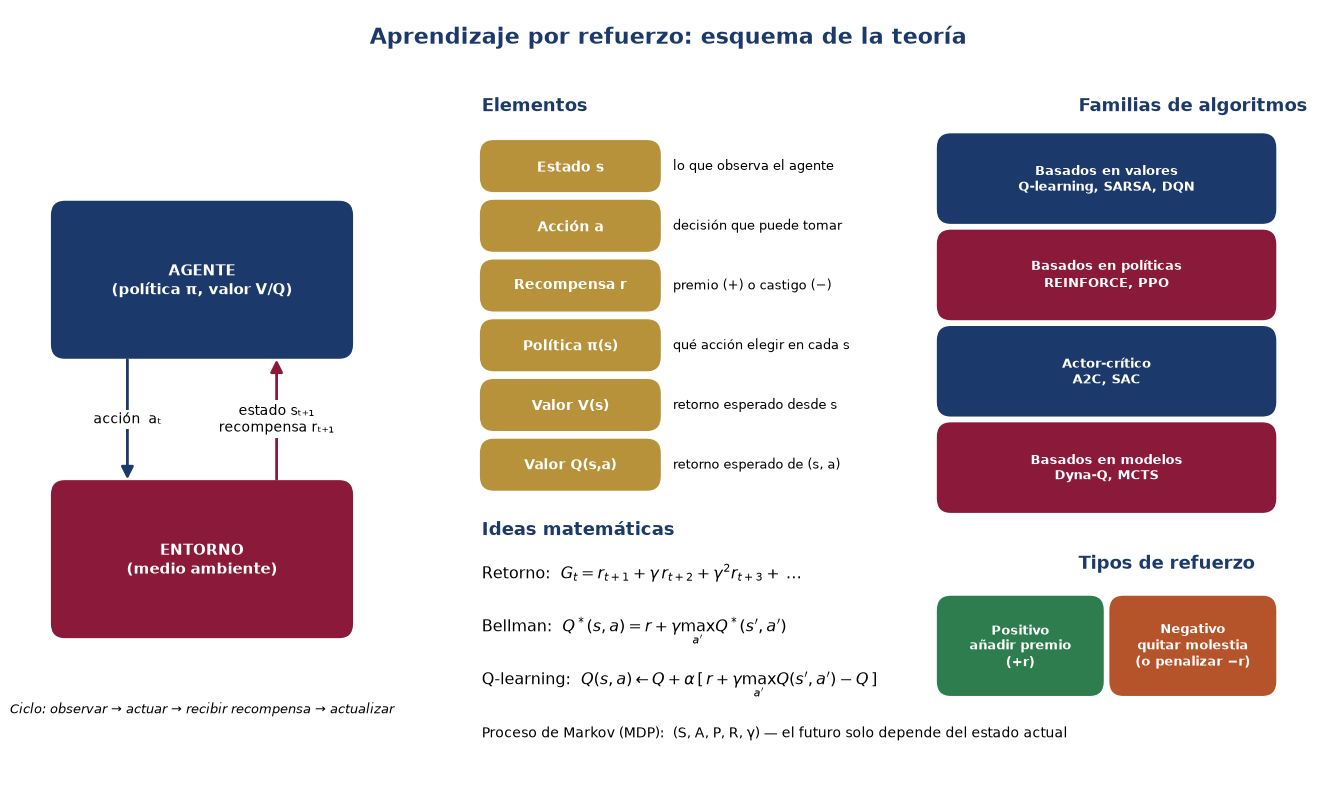

In [4]:
fig = figura_esquema()
plt.show()

# Actividad 25. Detecta los elementos del aprendizaje por refuerzo
**Objetivo:** identificar los conceptos básicos del RL en situaciones reales.
**Entregable:** tabla con los elementos de cada ejemplo + explicación (3 a 5 líneas) del papel de la recompensa.

In [5]:
act25 = tabla(A25_COLUMNAS, A25_FILAS)
display(act25.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

Elemento,a) Coche autónomo que aprende a estacionarse,b) Videojuego: monedas y enemigos,c) Recomendador de películas
Agente (quien aprende),El sistema de conducción del coche,El personaje controlado por la IA,El algoritmo recomendador
Medio ambiente (entorno),"Estacionamiento: cajones, otros autos, bordillos, física del vehículo","El nivel del juego: plataformas, monedas, enemigos, reglas","La plataforma y sus usuarios (catálogo, gustos, hábitos)"
Estado (s),"Posición, orientación y velocidad del auto; distancias medidas por sensores","Posición del personaje, de los enemigos y de las monedas; vidas restantes","Perfil del usuario, historial de películas vistas, hora y dispositivo"
Acción (a),"Girar el volante, acelerar, frenar, avanzar o retroceder","Moverse izquierda/derecha, saltar, esperar",Recomendar la película X (o una lista de ellas)
Recompensa (r),+100 al quedar bien estacionado; −50 por chocar; −1 por cada segundo que pasa,+1 por moneda; +50 por llegar a la meta; −10 por tocar un enemigo,+1 si el usuario la ve completa; +0.5 si da clic; −1 si la ignora o abandona
Política (π),Regla que decide la maniobra según lo que miden los sensores en cada instante,Regla que decide cuándo saltar o avanzar para tomar monedas esquivando enemigos,Regla que elige qué película mostrar a cada perfil de usuario
Valor (V o Q),Qué tan prometedora es una posición: alto si ya está alineado y cerca del cajón,Qué tan bueno es estar en cierto punto del nivel: alto cerca de monedas y lejos de enemigos,Satisfacción futura esperada del usuario si se le muestra esa película (no solo el clic inmediato)


### Gráfico: ciclo agente–entorno de cada ejemplo

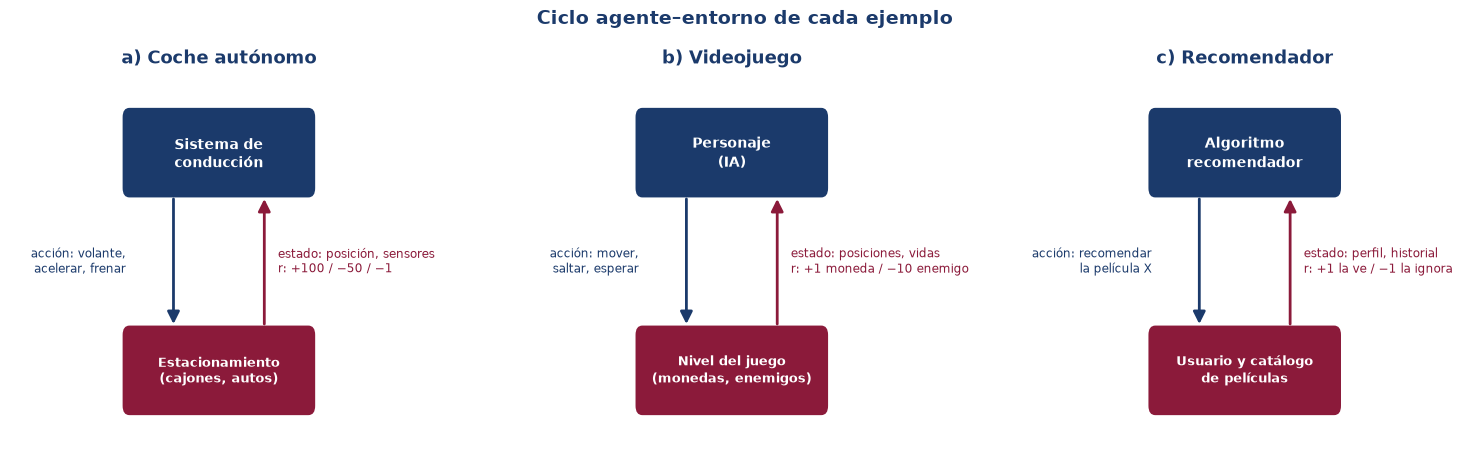

In [6]:
figura_ciclo_ejemplos()
plt.show()

### Papel de la recompensa en cada caso

In [7]:
for titulo, texto in A25_RECOMPENSA:
    display(Markdown(f"**{titulo}.** {texto}"))

**a) Coche autónomo.** La recompensa le dice al coche qué es estacionarse bien: premia el éxito final y castiga choques y tardanza. Con ella el auto descubre por ensayo y error que las maniobras suaves y precisas son las que más puntos acumulan en total.

**b) Videojuego.** Las monedas y la meta empujan al personaje a explorar y avanzar, mientras que el castigo por tocar enemigos le enseña a evitarlos. La recompensa es la única guía: nadie le explica las reglas, las deduce de lo que gana o pierde.

**c) Recomendador.** La recompensa mide si la recomendación fue buena (el usuario la vio o la ignoró). Así el sistema ajusta sus sugerencias a cada persona y, si la recompensa incluye el largo plazo, evita recomendar solo lo que genera clics rápidos.

# Actividad 26. Diseña tu propio entorno de aprendizaje por refuerzo
**Entregable:** descripción del agente (mínimo 5 renglones) y tabla con: agente, medio ambiente, estados, acciones, recompensas, política y cómo sabrás que aprendió.

In [8]:
display(Markdown(f"## {A26_TITULO}\n\n{A26_DESCRIPCION}"))
display(tabla(["Elemento", "Diseño"], A26_FILAS).style.set_properties(**{"text-align": "left"}).hide(axis="index"))

## AspiBot, el robot aspiradora que aprende su ruta

AspiBot es un robot aspiradora doméstico que no trae el mapa de la casa programado: lo va descubriendo mientras trabaja. Su propósito es llegar a las zonas sucias en el menor número de movimientos posible, cuidando su batería y evitando muebles. Al inicio se mueve casi al azar y choca con frecuencia; cada vez que limpia recibe un premio y cada movimiento o choque le cuesta puntos. Después de muchos intentos aprende la ruta más corta y segura desde su base hasta la suciedad, y la repite aunque cambien algunos detalles de la casa.

Elemento,Diseño
Agente,"AspiBot, robot aspiradora."
Medio ambiente,"Una casa dividida en una rejilla de 5×5 celdas, con muebles (obstáculos), una base de carga en la esquina y una zona sucia."
Posibles estados,"Su celda actual (fila, columna), nivel de batería (alto/medio/bajo) y si la zona sucia ya fue limpiada."
Acciones,"Mover arriba, abajo, izquierda o derecha; aspirar."
Recompensas / penalizaciones,+10 al limpiar la zona sucia; −1 por cada paso (gasta batería); −3 por chocar con un mueble o pared; −20 si se queda sin batería lejos de la base.
Política o estrategia,"ε-greedy sobre Q(s,a): al inicio explora mucho (ε alto) y con el tiempo explota (ε bajo), eligiendo la acción con mayor Q en cada celda."
¿Cómo sabré que aprendió?,El retorno por episodio sube y se estabiliza; el número de pasos baja hasta la ruta mínima; ya no choca; y la política greedy (sin exploración) llega a la suciedad siempre por el mismo camino corto.


### Comprobación: ¿aprende AspiBot? (simulación con Q-learning)

Retorno medio, primeros 20 episodios: -82.0
Retorno medio, últimos 20 episodios : 4.5
Pasos medios, últimos 20 episodios  : 6.3
Ruta greedy: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (3, 3)]


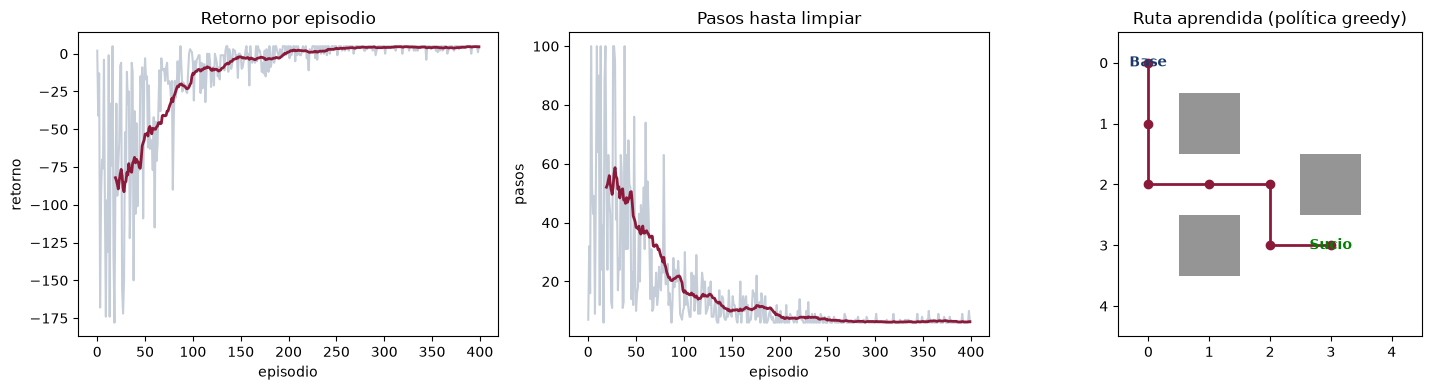

In [9]:
env = Rejilla()
Q_g, retornos, pasos = entrenar_rejilla(env)
ruta = ruta_greedy(env, Q_g)
print(f"Retorno medio, primeros 20 episodios: {retornos[:20].mean():.1f}")
print(f"Retorno medio, últimos 20 episodios : {retornos[-20:].mean():.1f}")
print(f"Pasos medios, últimos 20 episodios  : {pasos[-20:].mean():.1f}")
print("Ruta greedy:", ruta)
figura_rejilla(env, retornos, pasos, ruta)
plt.show()

### Conclusión

In [10]:
display(Markdown(A26_CONCLUSION))

Sabré que AspiBot aprendió correctamente cuando, sin explorar (ε = 0), llegue a la zona sucia en el mínimo de pasos de forma consistente, sin choques, y su retorno promedio por episodio se mantenga estable en un valor alto. En la simulación del notebook el retorno promedio pasa de ≈ −82 (primeros 20 episodios) a ≈ +4.5 (últimos 20), muy cerca de +5, el máximo posible en esa rejilla (5 pasos de −1 y la limpieza de +10).

# Actividad 27. Simula una iteración de Q-learning
**Objetivo:** aplicar la ecuación de Bellman para calcular Q(s,a).
**Parámetros:** $\alpha = 0.5$, $\gamma = 0.9$, $Q = 0$ al inicio.

Como el cuaderno no incluye el "ejemplo proporcionado", se crea un entorno similar con **3 estados** (S1, S2, S3) en línea y **3 acciones** (Izquierda, Derecha, Quedarse). Estas son sus reglas:

In [11]:
T = construir_entorno(r_s3_quedarse=3)
tabla_entorno(T)

,Estado s,Acción a,Siguiente s',Recompensa r
0,S1,Izquierda,S1,-1
1,S1,Derecha,S2,0
2,S1,Quedarse,S1,0
3,S2,Izquierda,S1,0
4,S2,Derecha,S3,1
5,S2,Quedarse,S2,0
6,S3,Izquierda,S2,5
7,S3,Derecha,S3,-1
8,S3,Quedarse,S3,3


**Fórmula:** $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$

Una *iteración* = un episodio corto de 6 experiencias elegidas para visitar los tres estados y repetir algunas parejas (s,a). Cada fila de la tabla es una actualización.

In [12]:
Q27, pasos27 = simular_trayectoria(T)
display(pasos27.drop(columns="Cálculo").round(4).style.hide(axis="index"))
print("Cálculos con la fórmula sustituida:")
for f in pasos27["Cálculo"]:
    print(" ", f)

Paso,s,a,r,s',Q anterior,"max Q(s',·)",Objetivo r+γ·max,Error TD,Q nuevo
1,S1,Derecha,0,S2,0.000000,0.000000,0.000000,0.000000,0.000000
2,S2,Derecha,1,S3,0.000000,0.000000,1.000000,1.000000,0.500000
3,S3,Quedarse,3,S3,0.000000,0.000000,3.000000,3.000000,1.500000
4,S3,Izquierda,5,S2,0.000000,0.500000,5.450000,5.450000,2.725000
5,S2,Derecha,1,S3,0.500000,2.725000,3.452500,2.952500,1.976200
6,S3,Izquierda,5,S2,2.725000,1.976200,6.778600,4.053600,4.751800


Cálculos con la fórmula sustituida:
  Q(S1,Derecha) = 0.0000 + 0.5·[0 + 0.9·0.0000 − 0.0000] = 0.0000
  Q(S2,Derecha) = 0.0000 + 0.5·[1 + 0.9·0.0000 − 0.0000] = 0.5000
  Q(S3,Quedarse) = 0.0000 + 0.5·[3 + 0.9·0.0000 − 0.0000] = 1.5000
  Q(S3,Izquierda) = 0.0000 + 0.5·[5 + 0.9·0.5000 − 0.0000] = 2.7250
  Q(S2,Derecha) = 0.5000 + 0.5·[1 + 0.9·2.7250 − 0.5000] = 1.9763
  Q(S3,Izquierda) = 2.7250 + 0.5·[5 + 0.9·1.9763 − 2.7250] = 4.7518


### Tabla Q final (después de las 6 actualizaciones)

In [13]:
display(Q27.round(4))
mejor = Q27.stack().idxmax()
print(f"Valor Q más alto: Q{mejor} = {Q27.stack().max():.4f}")

,Izquierda,Derecha,Quedarse
S1,0.0000,0.0000,0.0
S2,0.0000,1.9762,0.0
S3,4.7518,0.0000,1.5


Valor Q más alto: Q('S3', 'Izquierda') = 4.7518


### Gráfico: cómo evoluciona Q en las 6 actualizaciones

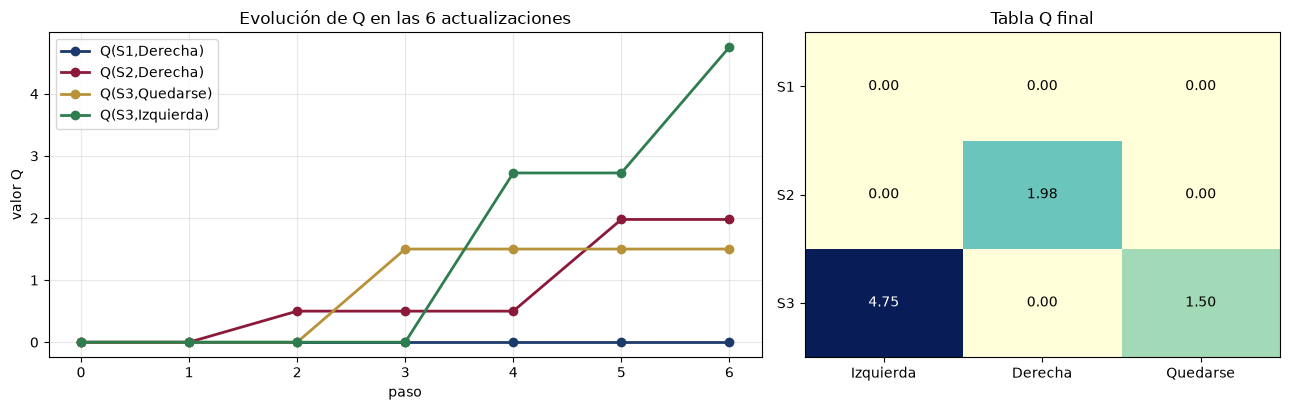

In [14]:
figura_q_pasos(T)
plt.show()

### Conclusión

In [15]:
for p in A27_CONCLUSION:
    display(Markdown(p))

El valor Q más alto es **Q(S3, Izquierda) = 4.7518**. Significa que, con lo aprendido hasta ahora, la mejor decisión estando en S3 es ir a la izquierda: esa acción da +5 de inmediato y además conduce a S2, un estado desde el cual el agente ya descubrió que puede volver a S3 con recompensa (Q(S2,Derecha) = 1.9763). Es decir, un Q alto resume la **recompensa inmediata más el valor futuro descontado** de elegir esa acción.

Observa que el aprendizaje se **propaga hacia atrás**: en el paso 5, Q(S2,Derecha) saltó de 0.5 a 1.9763 porque el siguiente estado (S3) ya tenía un valor alto (2.725). Con una sola iteración los valores todavía son pequeños y están incompletos (Q(S1,·) sigue en 0); al repetir muchos episodios, Q converge a los valores óptimos de la Actividad 29 (por ejemplo Q*(S3,Izquierda) ≈ 31.05).

# Actividad 28. Diseña un agente y elige su algoritmo
**Entregable:** descripción estructurada con entorno, acciones, recompensas, tipo de algoritmo y justificación.

In [16]:
display(Markdown(f"## Agente: {A28_AGENTE}"))
display(tabla(["Apartado", "Descripción"], A28_FILAS).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
display(Markdown("### Comparación de familias de algoritmos para este problema"))
display(tabla(["Algoritmo", "Familia", "Ideal cuando…", "¿Para este agente?"], A28_COMPARATIVA).style.set_properties(**{"text-align": "left"}).hide(axis="index"))

## Agente: Controlador de semáforos de un cruce de avenidas

Apartado,Descripción
Agente,Controlador inteligente de un semáforo en un cruce de dos avenidas.
Descripción del entorno,"Un cruce simulado (por ejemplo en SUMO) con flujo de autos variable según la hora. El estado incluye la longitud de la fila en cada carril, el tiempo de espera acumulado y la fase actual del semáforo; es un espacio muy grande (valores continuos)."
Acciones posibles,Mantener la fase actual o cambiar a la siguiente fase (verde para el otro sentido). Son pocas acciones discretas.
Recompensas esperadas,Recompensa = −(tiempo total de espera de los autos) en cada intervalo; −5 por cambios de fase demasiado frecuentes; +10 cuando se vacía una fila larga.
Tipo de algoritmo elegido,Basado en valores con aproximación por red neuronal: DQN (Deep Q-Network).
Justificación,"Con filas de longitud variable el número de estados es enorme, y una tabla Q como la de la Actividad 27 no cabría en memoria. DQN conserva la lógica de Q-learning pero estima Q(s,a) con una red neuronal. Como las acciones son pocas y discretas, un método basado en valores encaja bien (los basados en políticas, como PPO, se justifican sobre todo con acciones continuas). Además usa repetición de experiencias para aprender de forma estable."


### Comparación de familias de algoritmos para este problema

Algoritmo,Familia,Ideal cuando…,¿Para este agente?
Q-learning tabular,Valores,Pocos estados y acciones discretas,No: el espacio de estados es demasiado grande
DQN,Valores + red neuronal,"Muchos estados, acciones discretas",Sí: es la opción elegida
PPO / REINFORCE,Políticas,Acciones continuas o políticas estocásticas,"Posible, pero más complejo de lo necesario"
Dyna-Q,Basado en modelo,Simulaciones baratas y estados discretos,"Útil si se aprende un modelo del tráfico, pero el modelo es difícil de ajustar"


### Gráfico: la tabla Q no escala y qué algoritmo elegir

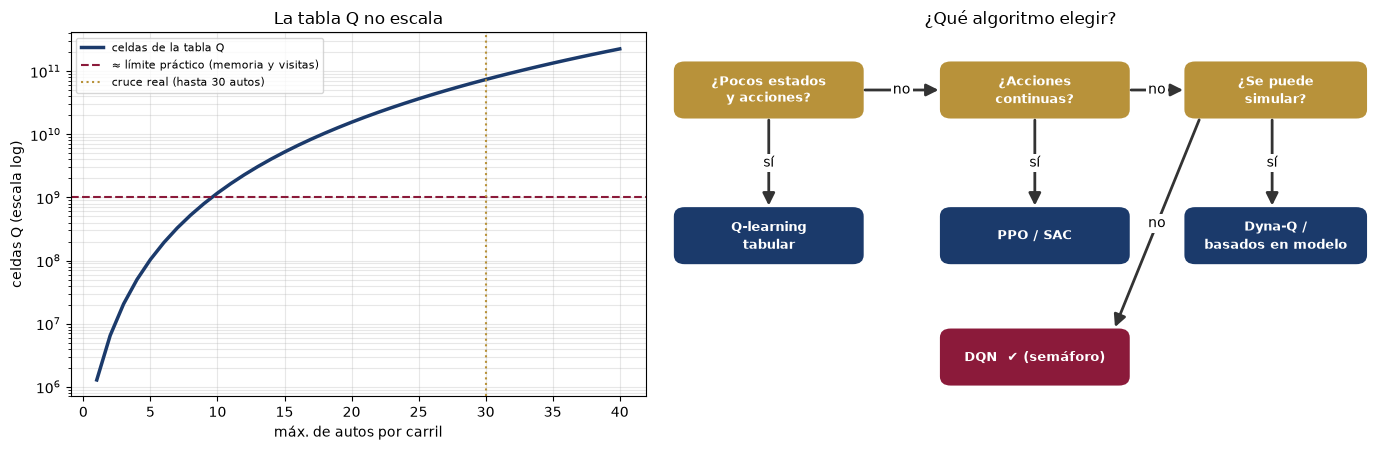

In [17]:
figura_algoritmo()
plt.show()

# Actividad 29. Calcula tu propia tabla Q
Se usa el mismo entorno de la Actividad 27, pero se cambia la recompensa de **(S3, Quedarse) de +3 a +6**. Se recalculan los valores Q de dos formas:
1. **Una iteración** (la misma trayectoria de 6 pasos de la Act. 27).
2. **Valores óptimos Q\*** resolviendo la ecuación de Bellman hasta converger, para comparar la política final.

In [18]:
T6 = construir_entorno(r_s3_quedarse=6)
Q27_nuevo, pasos29 = simular_trayectoria(T6)
display(Markdown("**Una iteración con +6 en (S3, Quedarse)**"))
display(pasos29.drop(columns="Cálculo").round(4).style.hide(axis="index"))
for f in pasos29["Cálculo"]:
    print(" ", f)
display(Markdown("**Comparación de la tabla tras una iteración**"))
comp = pd.concat({"Original (+3)": Q27, "Nueva (+6)": Q27_nuevo}, axis=1).round(4)
display(comp)

**Una iteración con +6 en (S3, Quedarse)**

Paso,s,a,r,s',Q anterior,"max Q(s',·)",Objetivo r+γ·max,Error TD,Q nuevo
1,S1,Derecha,0,S2,0.000000,0.000000,0.000000,0.000000,0.000000
2,S2,Derecha,1,S3,0.000000,0.000000,1.000000,1.000000,0.500000
3,S3,Quedarse,6,S3,0.000000,0.000000,6.000000,6.000000,3.000000
4,S3,Izquierda,5,S2,0.000000,0.500000,5.450000,5.450000,2.725000
5,S2,Derecha,1,S3,0.500000,3.000000,3.700000,3.200000,2.100000
6,S3,Izquierda,5,S2,2.725000,2.100000,6.890000,4.165000,4.807500


  Q(S1,Derecha) = 0.0000 + 0.5·[0 + 0.9·0.0000 − 0.0000] = 0.0000
  Q(S2,Derecha) = 0.0000 + 0.5·[1 + 0.9·0.0000 − 0.0000] = 0.5000
  Q(S3,Quedarse) = 0.0000 + 0.5·[6 + 0.9·0.0000 − 0.0000] = 3.0000
  Q(S3,Izquierda) = 0.0000 + 0.5·[5 + 0.9·0.5000 − 0.0000] = 2.7250
  Q(S2,Derecha) = 0.5000 + 0.5·[1 + 0.9·3.0000 − 0.5000] = 2.1000
  Q(S3,Izquierda) = 2.7250 + 0.5·[5 + 0.9·2.1000 − 2.7250] = 4.8075


**Comparación de la tabla tras una iteración**

Original (+3)                  Nueva (+6)                 
       Izquierda Derecha Quedarse  Izquierda Derecha Quedarse
S1        0.0000  0.0000      0.0     0.0000     0.0      0.0
S2        0.0000  1.9762      0.0     0.0000     2.1      0.0
S3        4.7518  0.0000      1.5     4.8075     0.0      3.0

<>:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
<>:4: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
<>:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
<>:4: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
C:\Users\alixpego\AppData\Local\Temp\ipykernel_26272\170766461.py:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
  display(Markdown("**Q\* óptima — original (+3)**")); display(Q_orig.round(2))
C:\Users\alixpego\AppData\Local\Temp\ipykernel_26272\170766461.py:4: SyntaxWarning: "\*" is 

**Q\* óptima — original (+3)**

,Izquierda,Derecha,Quedarse
S1,22.45,26.05,23.45
S2,23.45,28.95,26.05
S3,31.05,26.95,30.95


**Q\* óptima — nueva (+6)**

,Izquierda,Derecha,Quedarse
S1,43.55,49.5,44.55
S2,44.55,55.0,49.50
S3,54.50,53.0,60.00


**Política (mejor acción por estado)**

,Original (+3),Nueva (+6)
S1,Derecha,Derecha
S2,Derecha,Derecha
S3,Izquierda,Quedarse


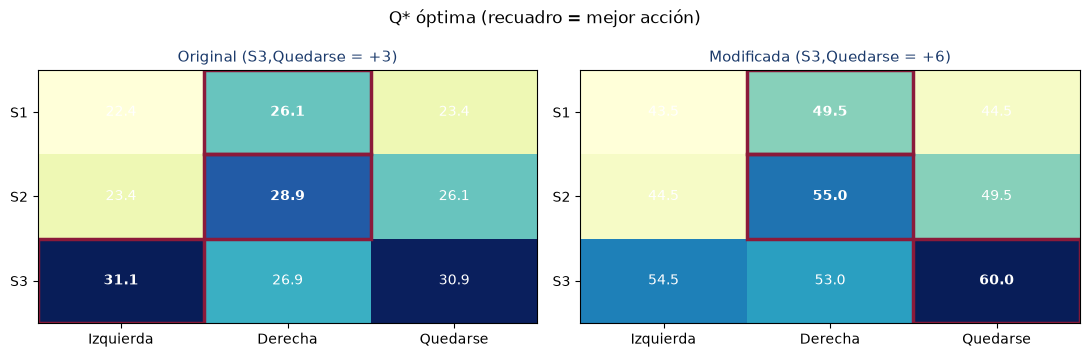

In [19]:
Q_orig = q_optima(T)       # recompensa original +3
Q_new = q_optima(T6)       # recompensa nueva +6
display(Markdown("**Q\* óptima — original (+3)**")); display(Q_orig.round(2))
display(Markdown("**Q\* óptima — nueva (+6)**"));  display(Q_new.round(2))
display(Markdown("**Política (mejor acción por estado)**"))
display(pd.DataFrame({"Original (+3)": politica(Q_orig), "Nueva (+6)": politica(Q_new)}))
figura_politicas(Q_orig, Q_new); plt.show()

### Gráfico: ¿a partir de qué recompensa conviene quedarse?

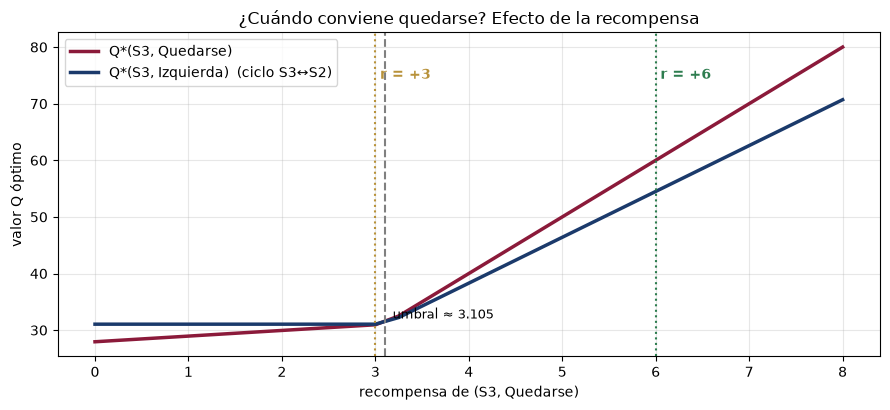

In [20]:
figura_umbral()
plt.show()

### Comprobación: Q-learning entrenado (no solo la solución exacta)

In [21]:
Q_ent = entrenar_q_learning(T6, episodios=500)
display(Q_ent.round(2))
print("Política aprendida por Q-learning:", politica(Q_ent).to_dict())
print("Diferencia máxima con Q* =", round(float((Q_ent - Q_new).abs().max().max()), 4))

,Izquierda,Derecha,Quedarse
S1,43.55,49.5,44.55
S2,44.55,55.0,49.50
S3,54.50,53.0,60.00


Política aprendida por Q-learning: {'S1': 'Derecha', 'S2': 'Derecha', 'S3': 'Quedarse'}
Diferencia máxima con Q* = 0.002


### Análisis

In [22]:
for p in A29_ANALISIS:
    display(Markdown("- " + p))

- **¿Qué cambió en el comportamiento?** En S3 la acción óptima pasó de **Izquierda** (Q* = 31.05 frente a 30.95 de Quedarse, casi empatadas) a **Quedarse** (Q* = 60 frente a 54.5). Antes al agente le convenía ir y venir entre S2 y S3 cobrando +5 y +1; ahora se queda en S3 cobrando +6 en cada paso. En S1 y S2 sigue yendo a la derecha, pero todos los valores Q suben porque llegar a S3 vale mucho más.

- **¿Por qué la nueva recompensa cambió la acción óptima?** Porque el valor de una acción es la recompensa inmediata más el valor futuro descontado. Quedarse en S3 produce 6 + 0.9·V(S3), es decir V(S3) = 6/(1−0.9) = 60, mientras que el ciclo S3→S2→S3 rinde solo 5.9 por cada dos pasos (≈ 54.5). Al duplicar la recompensa de Quedarse, esa opción supera al ciclo. Tras una sola iteración la tabla todavía no lo refleja del todo, pero con el entrenamiento completo de Q-learning la política converge a la de la solución exacta.

# Actividad 30. Diseña tu propio agente y aplica la lógica del aprendizaje por refuerzo
**Archivo a entregar:** `Actividad2_Tema4.2_NombreApellido.pdf` (según el cuaderno).

In [23]:
display(Markdown(f"## {A30_TITULO}\n\n**Propósito.** {A30_PROPOSITO}"))
display(pd.DataFrame([A30_FILA], columns=A30_COLUMNAS).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
display(Markdown("### Tipo de refuerzo y adaptación en el tiempo\n\n" + A30_TIPO_Y_ADAPTACION))

## SkyBot: dron repartidor que aprende a entregar paquetes

**Propósito.** SkyBot es un dron repartidor que debe entregar paquetes en un barrio sin conocer de antemano la mejor ruta. Por ensayo y error aprende a llegar al punto de entrega rápido, esquivar edificios y cables, y regresar a cargar antes de que se agote la batería.

Agente,Medio ambiente,Posibles estados,Acciones,Recompensas o penalizaciones,Política (estrategia),Cómo sabrás si aprendió correctamente
"SkyBot, dron repartidor","Barrio con edificios, cables, viento, una estación de carga y puntos de entrega","Posición (x, y, altura), nivel de batería, si lleva paquete, distancia al destino","Subir, bajar, avanzar en 4 direcciones, soltar paquete, volver a la estación",+20 por entregar; +5 por cargar con batería baja; −1 por cada paso; −10 por chocar; −30 si cae por batería,"ε-greedy con Q(s,a): explora al inicio y después elige la acción de mayor valor; volver a cargar si la batería < 20 %","Entrega en pocos pasos de forma consistente, sin choques ni caídas, con retorno promedio estable y alto"


### Tipo de refuerzo y adaptación en el tiempo

SkyBot usa ambos tipos de refuerzo. El refuerzo positivo es el premio que se añade al entregar el paquete (+20) y al cargar la batería a tiempo; el refuerzo negativo aparece cuando llegar a la estación elimina el estado aversivo de batería baja, y además se aplican penalizaciones (−10 por chocar, −1 por paso) que desalientan conductas. Con el tiempo reduce la exploración (ε baja), actualiza sus valores Q con cada experiencia y su política converge hacia rutas más cortas, seguras y con recargas oportunas.

### Gráfico: recompensas de SkyBot y efecto de ε

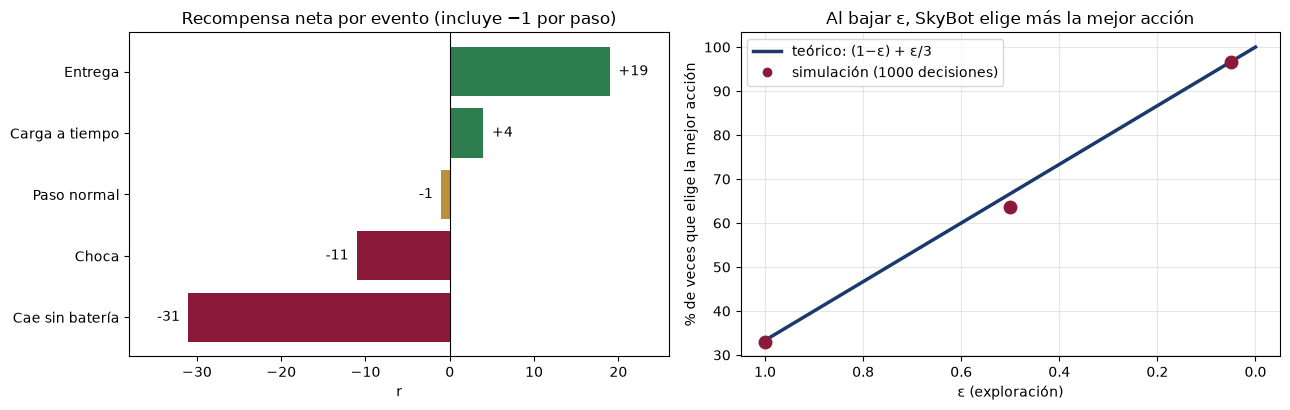

In [24]:
figura_skybot()
plt.show()

---
**Fin del cuaderno.** Repositorio: https://github.com/alixpeg0/aprendizaje-por-refuerzo-unidad4